# UCS420 Cognitive Computing
## Lab Assignment - NLP using Python II

In [1]:
# N Soma Sekhar
# Roll No: 1024170194

import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.probability import FreqDist

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

### Q1

In [2]:
text = "Chess is a game of patience, memory and imagination that has fascinated players for over fifteen centuries. Every game begins from the same position, yet the number of possible games is larger than the number of atoms in the observable universe! Modern engines like Stockfish and AlphaZero have changed how grandmasters prepare, revealing ideas that humans had ignored for decades. I enjoy rapid games online, but a slow classical game teaches me far more about planning and calculation. Losing is painful, although every loss shows exactly which habits I still need to fix. For me, chess isn't just a hobby; it's a daily workout for the mind."
print(text)

Chess is a game of patience, memory and imagination that has fascinated players for over fifteen centuries. Every game begins from the same position, yet the number of possible games is larger than the number of atoms in the observable universe! Modern engines like Stockfish and AlphaZero have changed how grandmasters prepare, revealing ideas that humans had ignored for decades. I enjoy rapid games online, but a slow classical game teaches me far more about planning and calculation. Losing is painful, although every loss shows exactly which habits I still need to fix. For me, chess isn't just a hobby; it's a daily workout for the mind.


1.

In [3]:
clean = text.lower()
clean = re.sub(r'[^\w\s]', '', clean)
print(clean)

chess is a game of patience memory and imagination that has fascinated players for over fifteen centuries every game begins from the same position yet the number of possible games is larger than the number of atoms in the observable universe modern engines like stockfish and alphazero have changed how grandmasters prepare revealing ideas that humans had ignored for decades i enjoy rapid games online but a slow classical game teaches me far more about planning and calculation losing is painful although every loss shows exactly which habits i still need to fix for me chess isnt just a hobby its a daily workout for the mind


2.

In [4]:
sents = sent_tokenize(text)
for s in sents:
    print(s)

words = word_tokenize(clean)
print(words)
print(len(words))

Chess is a game of patience, memory and imagination that has fascinated players for over fifteen centuries.
Every game begins from the same position, yet the number of possible games is larger than the number of atoms in the observable universe!
Modern engines like Stockfish and AlphaZero have changed how grandmasters prepare, revealing ideas that humans had ignored for decades.
I enjoy rapid games online, but a slow classical game teaches me far more about planning and calculation.
Losing is painful, although every loss shows exactly which habits I still need to fix.
For me, chess isn't just a hobby; it's a daily workout for the mind.
['chess', 'is', 'a', 'game', 'of', 'patience', 'memory', 'and', 'imagination', 'that', 'has', 'fascinated', 'players', 'for', 'over', 'fifteen', 'centuries', 'every', 'game', 'begins', 'from', 'the', 'same', 'position', 'yet', 'the', 'number', 'of', 'possible', 'games', 'is', 'larger', 'than', 'the', 'number', 'of', 'atoms', 'in', 'the', 'observable', 'u

3.

In [5]:
s1 = text.split()
s2 = word_tokenize(text)
print(s1)
print(len(s1))
print(s2)
print(len(s2))

['Chess', 'is', 'a', 'game', 'of', 'patience,', 'memory', 'and', 'imagination', 'that', 'has', 'fascinated', 'players', 'for', 'over', 'fifteen', 'centuries.', 'Every', 'game', 'begins', 'from', 'the', 'same', 'position,', 'yet', 'the', 'number', 'of', 'possible', 'games', 'is', 'larger', 'than', 'the', 'number', 'of', 'atoms', 'in', 'the', 'observable', 'universe!', 'Modern', 'engines', 'like', 'Stockfish', 'and', 'AlphaZero', 'have', 'changed', 'how', 'grandmasters', 'prepare,', 'revealing', 'ideas', 'that', 'humans', 'had', 'ignored', 'for', 'decades.', 'I', 'enjoy', 'rapid', 'games', 'online,', 'but', 'a', 'slow', 'classical', 'game', 'teaches', 'me', 'far', 'more', 'about', 'planning', 'and', 'calculation.', 'Losing', 'is', 'painful,', 'although', 'every', 'loss', 'shows', 'exactly', 'which', 'habits', 'I', 'still', 'need', 'to', 'fix.', 'For', 'me,', 'chess', "isn't", 'just', 'a', 'hobby;', "it's", 'a', 'daily', 'workout', 'for', 'the', 'mind.']
107
['Chess', 'is', 'a', 'game', '

split() only splits on spaces, so punctuation stays attached to words, like "centuries." and "hobby;". word_tokenize() makes punctuation separate tokens, and it also splits "isn't" into "is" and "n't". That is why word_tokenize gives more tokens.

4.

In [6]:
sw = stopwords.words('english')
filtered = []
for w in words:
    if w not in sw:
        filtered.append(w)
print(filtered)

['chess', 'game', 'patience', 'memory', 'imagination', 'fascinated', 'players', 'fifteen', 'centuries', 'every', 'game', 'begins', 'position', 'yet', 'number', 'possible', 'games', 'larger', 'number', 'atoms', 'observable', 'universe', 'modern', 'engines', 'like', 'stockfish', 'alphazero', 'changed', 'grandmasters', 'prepare', 'revealing', 'ideas', 'humans', 'ignored', 'decades', 'enjoy', 'rapid', 'games', 'online', 'slow', 'classical', 'game', 'teaches', 'far', 'planning', 'calculation', 'losing', 'painful', 'although', 'every', 'loss', 'shows', 'exactly', 'habits', 'still', 'need', 'fix', 'chess', 'isnt', 'hobby', 'daily', 'workout', 'mind']


5.

[('game', 3), ('chess', 2), ('every', 2), ('number', 2), ('games', 2), ('patience', 1), ('memory', 1), ('imagination', 1), ('fascinated', 1), ('players', 1)]


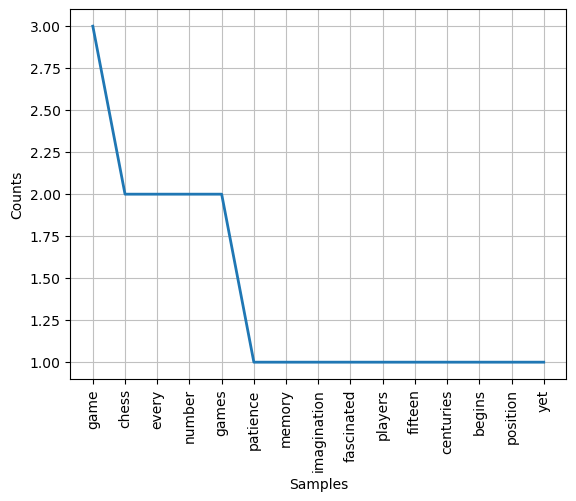

In [7]:
fd = FreqDist(filtered)
print(fd.most_common(10))
fd.plot(15)
plt.show()

### Q2

1.

In [8]:
alpha = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print(alpha)

['chess', 'is', 'a', 'game', 'of', 'patience', 'memory', 'and', 'imagination', 'that', 'has', 'fascinated', 'players', 'for', 'over', 'fifteen', 'centuries', 'every', 'game', 'begins', 'from', 'the', 'same', 'position', 'yet', 'the', 'number', 'of', 'possible', 'games', 'is', 'larger', 'than', 'the', 'number', 'of', 'atoms', 'in', 'the', 'observable', 'universe', 'modern', 'engines', 'like', 'stockfish', 'and', 'alphazero', 'have', 'changed', 'how', 'grandmasters', 'prepare', 'revealing', 'ideas', 'that', 'humans', 'had', 'ignored', 'for', 'decades', 'i', 'enjoy', 'rapid', 'games', 'online', 'but', 'a', 'slow', 'classical', 'game', 'teaches', 'me', 'far', 'more', 'about', 'planning', 'and', 'calculation', 'losing', 'is', 'painful', 'although', 'every', 'loss', 'shows', 'exactly', 'which', 'habits', 'i', 'still', 'need', 'to', 'fix', 'for', 'me', 'chess', 'isn', 't', 'just', 'a', 'hobby', 'it', 's', 'a', 'daily', 'workout', 'for', 'the', 'mind']


2.

In [9]:
words2 = []
for w in alpha:
    if w not in sw:
        words2.append(w)
print(words2)

['chess', 'game', 'patience', 'memory', 'imagination', 'fascinated', 'players', 'fifteen', 'centuries', 'every', 'game', 'begins', 'position', 'yet', 'number', 'possible', 'games', 'larger', 'number', 'atoms', 'observable', 'universe', 'modern', 'engines', 'like', 'stockfish', 'alphazero', 'changed', 'grandmasters', 'prepare', 'revealing', 'ideas', 'humans', 'ignored', 'decades', 'enjoy', 'rapid', 'games', 'online', 'slow', 'classical', 'game', 'teaches', 'far', 'planning', 'calculation', 'losing', 'painful', 'although', 'every', 'loss', 'shows', 'exactly', 'habits', 'still', 'need', 'fix', 'chess', 'hobby', 'daily', 'workout', 'mind']


3.

In [10]:
ps = PorterStemmer()
stems = []
for w in words2:
    stems.append(ps.stem(w))
print(stems)

['chess', 'game', 'patienc', 'memori', 'imagin', 'fascin', 'player', 'fifteen', 'centuri', 'everi', 'game', 'begin', 'posit', 'yet', 'number', 'possibl', 'game', 'larger', 'number', 'atom', 'observ', 'univers', 'modern', 'engin', 'like', 'stockfish', 'alphazero', 'chang', 'grandmast', 'prepar', 'reveal', 'idea', 'human', 'ignor', 'decad', 'enjoy', 'rapid', 'game', 'onlin', 'slow', 'classic', 'game', 'teach', 'far', 'plan', 'calcul', 'lose', 'pain', 'although', 'everi', 'loss', 'show', 'exactli', 'habit', 'still', 'need', 'fix', 'chess', 'hobbi', 'daili', 'workout', 'mind']


4.

In [11]:
lem = WordNetLemmatizer()
lemmas = []
for w in words2:
    lemmas.append(lem.lemmatize(w))
print(lemmas)

['chess', 'game', 'patience', 'memory', 'imagination', 'fascinated', 'player', 'fifteen', 'century', 'every', 'game', 'begin', 'position', 'yet', 'number', 'possible', 'game', 'larger', 'number', 'atom', 'observable', 'universe', 'modern', 'engine', 'like', 'stockfish', 'alphazero', 'changed', 'grandmaster', 'prepare', 'revealing', 'idea', 'human', 'ignored', 'decade', 'enjoy', 'rapid', 'game', 'online', 'slow', 'classical', 'game', 'teach', 'far', 'planning', 'calculation', 'losing', 'painful', 'although', 'every', 'loss', 'show', 'exactly', 'habit', 'still', 'need', 'fix', 'chess', 'hobby', 'daily', 'workout', 'mind']


5.

In [12]:
df = pd.DataFrame({'word': words2, 'stem': stems, 'lemma': lemmas})
df

,word,stem,lemma
0,chess,chess,chess
1,game,game,game
2,patience,patienc,patience
3,memory,memori,memory
4,imagination,imagin,imagination
...,...,...,...
57,chess,chess,chess
58,hobby,hobbi,hobby
59,daily,daili,daily
60,workout,workout,workout


Stemming just cuts off the end of the word, so it sometimes gives words that don't exist, like "imagin", "univers" and "daili". Lemmatization gives proper dictionary words like "century" and "grandmaster".

I would use stemming when speed matters and the exact word doesn't, for example in search engines. I would use lemmatization when the output has to make sense, for example in chatbots or sentiment analysis.

### Q3

In [13]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = ["Electric car sales hit a record high as battery prices fall, and electric car makers expect charging demand to double.",
         "The new smartphone camera is brilliant in low light, but the smartphone battery drains quickly and the camera app crashes.",
         "Heavy monsoon rains flood city streets; monsoon flooding closes schools as rescue teams evacuate flood victims."]

1.

In [14]:
cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)
print(cv.get_feature_names_out())
print(bow.toarray())

['app' 'battery' 'brilliant' 'camera' 'car' 'charging' 'city' 'closes'
 'crashes' 'demand' 'double' 'drains' 'electric' 'evacuate' 'expect'
 'fall' 'flood' 'flooding' 'heavy' 'high' 'hit' 'light' 'low' 'makers'
 'monsoon' 'new' 'prices' 'quickly' 'rains' 'record' 'rescue' 'sales'
 'schools' 'smartphone' 'streets' 'teams' 'victims']
[[0 1 0 0 2 1 0 0 0 1 1 0 2 0 1 1 0 0 0 1 1 0 0 1 0 0 1 0 0 1 0 1 0 0 0 0
  0]
 [1 1 1 2 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0 2 0 0
  0]
 [0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 2 1 1 0 0 0 0 0 2 0 0 0 1 0 1 0 1 0 1 1
  1]]


2.

In [15]:
tf = TfidfVectorizer(stop_words='english')
X = tf.fit_transform(texts)
tdf = pd.DataFrame(X.toarray(), columns=tf.get_feature_names_out())
tdf.round(2)

,app,battery,brilliant,camera,car,charging,city,closes,crashes,demand,...,quickly,rains,record,rescue,sales,schools,smartphone,streets,teams,victims
0,0.00,0.17,0.00,0.00,0.45,0.23,0.00,0.00,0.00,0.23,...,0.00,0.00,0.23,0.00,0.23,0.00,0.00,0.00,0.00,0.00
1,0.25,0.19,0.25,0.49,0.00,0.00,0.00,0.00,0.25,0.00,...,0.25,0.00,0.00,0.00,0.00,0.00,0.49,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.23,0.23,0.00,0.00,...,0.00,0.23,0.00,0.23,0.00,0.23,0.00,0.23,0.23,0.23


3.

In [16]:
for i in range(3):
    row = tdf.iloc[i].sort_values(ascending=False)
    print("Text", i + 1, ":", list(row.index[:3]))

Text 1 : ['electric', 'car', 'double']
Text 2 : ['camera', 'smartphone', 'app']
Text 3 : ['monsoon', 'flood', 'heavy']


The top words are the ones repeated in a text but not used in the other texts: electric and car for text 1, smartphone and camera for text 2, flood and monsoon for text 3. "battery" is in 2 texts, so it gets a lower score. TF-IDF gives more weight to words that are special to one document.

### Q4

In [17]:
t1 = "Artificial intelligence lets computers learn patterns from large amounts of data. Machine learning models are trained on examples and then make predictions on new data. Deep neural networks power image recognition, speech assistants and language translation. AI systems need careful evaluation because their decisions can be biased by the training data."
t2 = "Blockchain is a distributed ledger that records transactions across many computers. Each block stores data and a cryptographic hash that links it to the previous block. Because the ledger is shared and verified by consensus, records are very hard to tamper with. Blockchain systems power cryptocurrencies, supply-chain tracking and digital identity."

1.

In [18]:
def prep(t):
    toks = word_tokenize(t.lower())
    res = []
    for w in toks:
        if w.isalpha() and w not in sw:
            res.append(lem.lemmatize(w))
    return res

a = prep(t1)
b = prep(t2)
print(a)
print(b)

['artificial', 'intelligence', 'let', 'computer', 'learn', 'pattern', 'large', 'amount', 'data', 'machine', 'learning', 'model', 'trained', 'example', 'make', 'prediction', 'new', 'data', 'deep', 'neural', 'network', 'power', 'image', 'recognition', 'speech', 'assistant', 'language', 'translation', 'ai', 'system', 'need', 'careful', 'evaluation', 'decision', 'biased', 'training', 'data']
['blockchain', 'distributed', 'ledger', 'record', 'transaction', 'across', 'many', 'computer', 'block', 'store', 'data', 'cryptographic', 'hash', 'link', 'previous', 'block', 'ledger', 'shared', 'verified', 'consensus', 'record', 'hard', 'tamper', 'blockchain', 'system', 'power', 'cryptocurrencies', 'tracking', 'digital', 'identity']


2a. Jaccard

In [19]:
A = set(a)
B = set(b)
jac = len(A & B) / len(A | B)
print(A & B)
print("jaccard:", jac)

{'power', 'data', 'system', 'computer'}
jaccard: 0.07017543859649122


2b. Cosine

In [20]:
from sklearn.metrics.pairwise import cosine_similarity

v = TfidfVectorizer()
m = v.fit_transform([" ".join(a), " ".join(b)])
print("cosine:", cosine_similarity(m[0], m[1])[0][0])

cosine: 0.08311302864139006


2c. Both values are low, so both metrics agree that the two texts are about different topics. Only words like data, computer, power and system are common. I think cosine similarity is better because it also counts how many times a word appears and how rare it is. Jaccard only checks whether a word is present or not.

### Q5

In [21]:
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

reviews = ["The food delivery app is fantastic! Orders arrive hot, the tracking is accurate and the support team is super friendly.",
           "Terrible experience. My order was 50 minutes late, the fries were cold and nobody answered my complaint.",
           "The app works. I ordered a sandwich and it arrived at the time shown.",
           "Love the new interface, checkout is quick and the discounts are genuinely useful.",
           "Delivery was okay but the packaging was damaged and the drink had leaked everywhere, really disappointing."]

1. and 2.

In [22]:
sia = SentimentIntensityAnalyzer()
labels = []
for r in reviews:
    tb = TextBlob(r)
    score = sia.polarity_scores(r)['compound']
    if score >= 0.05:
        lab = "Positive"
    elif score <= -0.05:
        lab = "Negative"
    else:
        lab = "Neutral"
    labels.append(lab)
    print(r)
    print("polarity:", round(tb.sentiment.polarity, 2), "subjectivity:", round(tb.sentiment.subjectivity, 2), "vader:", score, "->", lab)
    print()

The food delivery app is fantastic! Orders arrive hot, the tracking is accurate and the support team is super friendly.
polarity: 0.37 subjectivity: 0.71 vader: 0.9286 -> Positive

Terrible experience. My order was 50 minutes late, the fries were cold and nobody answered my complaint.
polarity: -0.55 subjectivity: 0.7 vader: -0.6486 -> Negative

The app works. I ordered a sandwich and it arrived at the time shown.
polarity: 0.0 subjectivity: 0.0 vader: 0.0 -> Neutral

Love the new interface, checkout is quick and the discounts are genuinely useful.
polarity: 0.32 subjectivity: 0.39 vader: 0.7964 -> Positive

Delivery was okay but the packaging was damaged and the drink had leaked everywhere, really disappointing.
polarity: -0.05 subjectivity: 0.6 vader: -0.902 -> Negative



3.

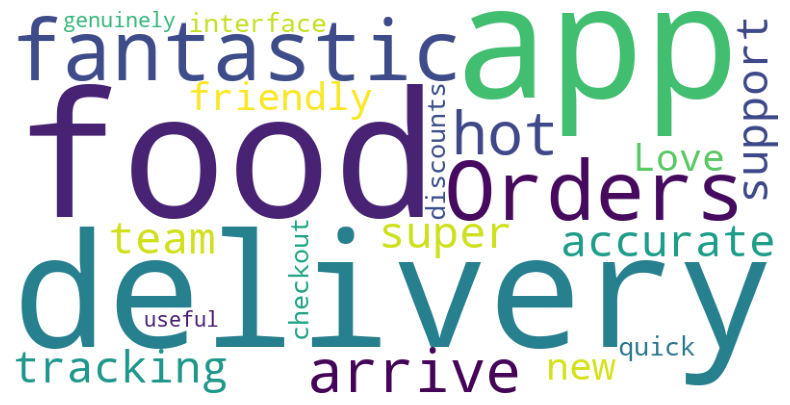

In [23]:
from wordcloud import WordCloud

pos = ""
for i in range(len(reviews)):
    if labels[i] == "Positive":
        pos = pos + " " + reviews[i]

wc = WordCloud(width=800, height=400, background_color='white', random_state=1).generate(pos)
plt.figure(figsize=(10, 5))
plt.imshow(wc)
plt.axis('off')
plt.show()

### Q6

In [24]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tf.random.set_seed(1)

data = '''The ocean covers most of our planet and holds life we have barely explored.
Deep below the waves, strange fish glow in the dark and giant squid hunt in silence.
Coral reefs are the cities of the ocean, full of colour, movement and life.
Warm water and pollution are now bleaching the reefs and the fish are leaving.
Scientists study the ocean to understand how the planet breathes and changes.
If we protect the ocean today, the reefs and the fish will still be there tomorrow.
The ocean gives us food, rain and air, and the ocean asks only for our care.'''

1.

In [25]:
tok = Tokenizer()
tok.fit_on_texts([data])
total = len(tok.word_index) + 1
print(total)
print(tok.word_index)

64
{'the': 1, 'and': 2, 'ocean': 3, 'of': 4, 'fish': 5, 'reefs': 6, 'are': 7, 'our': 8, 'planet': 9, 'life': 10, 'we': 11, 'in': 12, 'covers': 13, 'most': 14, 'holds': 15, 'have': 16, 'barely': 17, 'explored': 18, 'deep': 19, 'below': 20, 'waves': 21, 'strange': 22, 'glow': 23, 'dark': 24, 'giant': 25, 'squid': 26, 'hunt': 27, 'silence': 28, 'coral': 29, 'cities': 30, 'full': 31, 'colour': 32, 'movement': 33, 'warm': 34, 'water': 35, 'pollution': 36, 'now': 37, 'bleaching': 38, 'leaving': 39, 'scientists': 40, 'study': 41, 'to': 42, 'understand': 43, 'how': 44, 'breathes': 45, 'changes': 46, 'if': 47, 'protect': 48, 'today': 49, 'will': 50, 'still': 51, 'be': 52, 'there': 53, 'tomorrow': 54, 'gives': 55, 'us': 56, 'food': 57, 'rain': 58, 'air': 59, 'asks': 60, 'only': 61, 'for': 62, 'care': 63}


2.

In [26]:
seqs = []
for line in data.lower().split("\n"):
    nums = tok.texts_to_sequences([line])[0]
    for i in range(1, len(nums)):
        seqs.append(nums[:i+1])

maxlen = max([len(s) for s in seqs])
seqs = np.array(pad_sequences(seqs, maxlen=maxlen, padding='pre'))
x = seqs[:, :-1]
y = seqs[:, -1]
print(x.shape, y.shape)

model = Sequential()
model.add(Embedding(total, 32))
model.add(LSTM(100))
model.add(Dense(total, activation='softmax'))
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

(95, 15) (95,)


3.

In [27]:
hist = model.fit(x, y, epochs=250, verbose=0)
print("accuracy:", hist.history['accuracy'][-1])

accuracy: 0.9894737005233765


In [28]:
def generate(seed, n):
    out = seed
    for i in range(n):
        s = tok.texts_to_sequences([out])[0]
        s = pad_sequences([s], maxlen=maxlen-1, padding='pre')
        p = np.argmax(model.predict(s, verbose=0))
        for w, idx in tok.word_index.items():
            if idx == p:
                out = out + " " + w
                break
    return out

print(generate("ocean", 10))
print(generate("coral", 10))
print(generate("scientists", 10))

ocean gives us and pollution are the reefs and the ocean


coral reefs are the cities of the ocean full of colour


scientists study the ocean to understand how the planet breathes and


The model learned the paragraph, so the generated lines mostly repeat phrases from it. It would need much more text to write new sentences.